# RetainIQ: Exploratory Data Analysis

This notebook explores the churn dataset before any modelling. It reuses the same loading, cleaning and helper functions as the app (`src/`), so the numbers here match the dashboard.

Run it from the project root after `python -m src.data_loader`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader import load_raw_dataset, clean_dataset, data_quality_report, is_synthetic_dataset
from src.eda import add_derived_columns, churn_rate_by, generate_insights, correlation_with_churn
from src.config import NUMERIC_FEATURES, CATEGORICAL_FEATURES

# src.eda selects a non-GUI backend; switch back so figures show in the notebook
%matplotlib inline
sns.set_theme(style='whitegrid')
palette = {'Retained': '#2BB7A5', 'Churned': '#E8636F'}
print('Synthetic data?', is_synthetic_dataset())

Synthetic data? False


## 1. Load and check the data

In [2]:
raw = load_raw_dataset()
print('Raw shape:', raw.shape)
raw.head()

Raw shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print('TotalCharges dtype in raw file:', raw['TotalCharges'].dtype)
blank = raw[raw['TotalCharges'].astype(str).str.strip() == '']
print('Rows with blank TotalCharges:', len(blank), '| their tenure values:', sorted(blank['tenure'].unique()))

TotalCharges dtype in raw file: str
Rows with blank TotalCharges: 11 | their tenure values: [np.int64(0)]


Blank `TotalCharges` appear only for customers with tenure 0 (not billed yet), so the cleaning step sets them to 0.

In [4]:
df = add_derived_columns(clean_dataset(raw))
report = data_quality_report(df)
{k: report[k] for k in ['rows', 'columns', 'missing_values', 'duplicate_rows', 'duplicate_customer_ids', 'churn_counts', 'churn_rate']}

{'rows': 7043,
 'columns': 26,
 'missing_values': {},
 'duplicate_rows': 0,
 'duplicate_customer_ids': 0,
 'churn_counts': {'No': 5174, 'Yes': 1869},
 'churn_rate': 0.2653698707936959}

In [5]:
df.dtypes.to_frame('dtype').T

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ChurnFlag,Status,TenureBand,ChargeTier,Segment
dtype,str,str,object,str,str,int64,str,str,str,str,...,str,str,float64,float64,object,int64,str,category,category,category


## 2. Target distribution

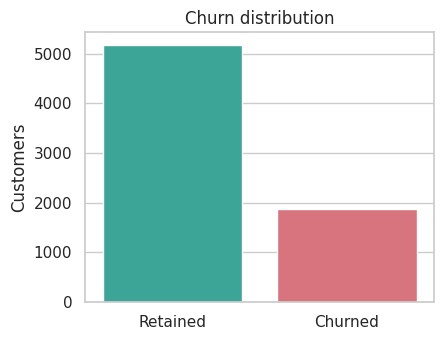

Churn rate: 26.5% -> imbalanced, so we use class weights and look at recall/F1/ROC-AUC, not accuracy alone.


In [6]:
fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.countplot(data=df, x='Status', hue='Status', palette=palette, order=['Retained', 'Churned'], legend=False, ax=ax)
ax.set(title='Churn distribution', xlabel='', ylabel='Customers')
plt.show()
print(f"Churn rate: {df['ChurnFlag'].mean():.1%} -> imbalanced, so we use class weights and look at recall/F1/ROC-AUC, not accuracy alone.")

## 3. Numerical features

In [7]:
df[NUMERIC_FEATURES].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


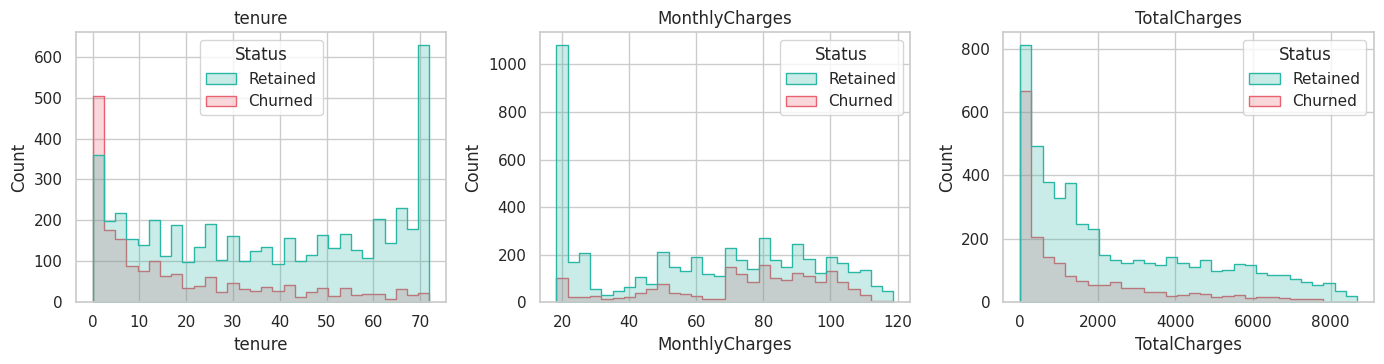

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, column in zip(axes, NUMERIC_FEATURES):
    sns.histplot(data=df, x=column, hue='Status', palette=palette, bins=30, element='step', ax=ax)
    ax.set_title(column)
plt.tight_layout()
plt.show()

## 4. Tenure and monthly charges vs churn

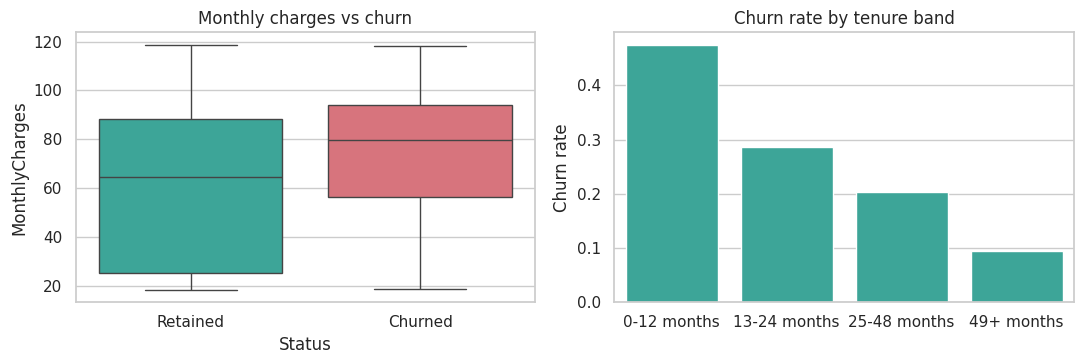

,TenureBand,customers,churned,churn_rate,avg_tenure,avg_monthly_charges
0,0-12 months,2186,1037,0.474,4.731,56.098
1,13-24 months,1024,294,0.287,18.352,61.357
2,25-48 months,1594,325,0.204,36.191,65.931
3,49+ months,2239,213,0.095,63.049,73.945


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.boxplot(data=df, x='Status', y='MonthlyCharges', hue='Status', palette=palette, order=['Retained', 'Churned'], legend=False, ax=axes[0])
axes[0].set_title('Monthly charges vs churn')
table = churn_rate_by(df, 'TenureBand')
sns.barplot(data=table, x='TenureBand', y='churn_rate', color='#2BB7A5', ax=axes[1])
axes[1].set(title='Churn rate by tenure band', xlabel='', ylabel='Churn rate')
plt.tight_layout()
plt.show()
table.round(3)

## 5. Categorical features

In [10]:
rows = []
for column in CATEGORICAL_FEATURES:
    table = churn_rate_by(df, column)
    top = table.sort_values('churn_rate').iloc[-1]
    bottom = table.sort_values('churn_rate').iloc[0]
    rows.append({'feature': column, 'highest churn': f"{top[column]} ({top['churn_rate']:.1%})", 'lowest churn': f"{bottom[column]} ({bottom['churn_rate']:.1%})", 'spread (pts)': round((top['churn_rate'] - bottom['churn_rate']) * 100, 1)})
pd.DataFrame(rows).sort_values('spread (pts)', ascending=False).reset_index(drop=True)

,feature,highest churn,lowest churn,spread (pts)
0,Contract,Month-to-month (42.7%),Two year (2.8%),39.9
1,InternetService,Fiber optic (41.9%),No (7.4%),34.5
2,OnlineSecurity,No (41.8%),No internet service (7.4%),34.4
3,TechSupport,No (41.6%),No internet service (7.4%),34.2
4,OnlineBackup,No (39.9%),No internet service (7.4%),32.5
5,DeviceProtection,No (39.1%),No internet service (7.4%),31.7
6,PaymentMethod,Electronic check (45.3%),Credit card (automatic) (15.2%),30.0
7,StreamingMovies,No (33.7%),No internet service (7.4%),26.3
8,StreamingTV,No (33.5%),No internet service (7.4%),26.1
9,SeniorCitizen,Yes (41.7%),No (23.6%),18.1


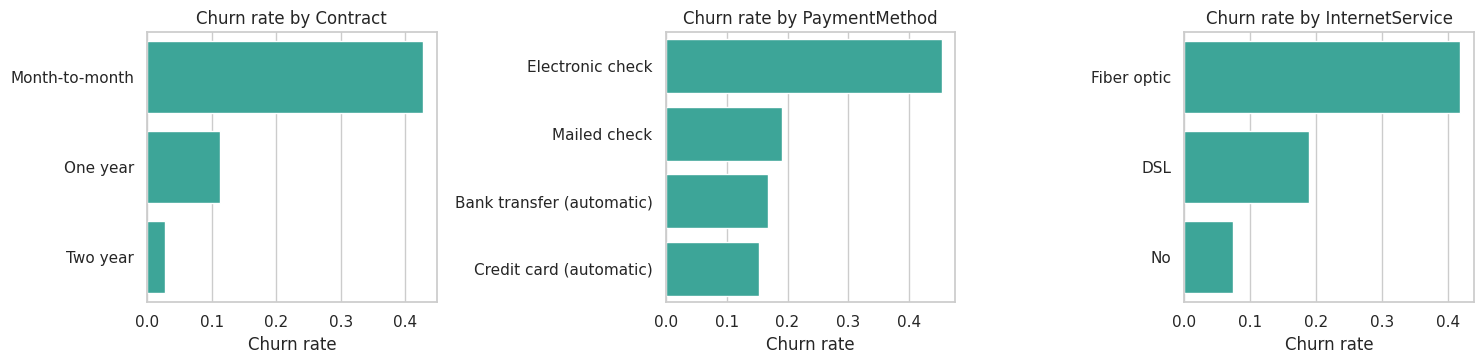

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, column in zip(axes, ['Contract', 'PaymentMethod', 'InternetService']):
    table = churn_rate_by(df, column).sort_values('churn_rate', ascending=False)
    sns.barplot(data=table, y=column, x='churn_rate', color='#2BB7A5', ax=ax)
    ax.set(title=f'Churn rate by {column}', xlabel='Churn rate', ylabel='')
plt.tight_layout()
plt.show()

## 6. Correlation (numeric features)

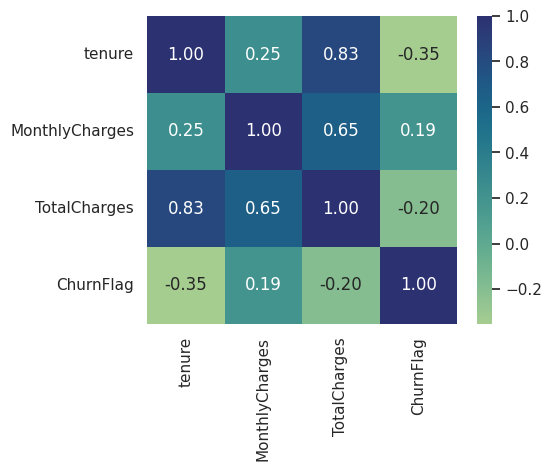

In [12]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(correlation_with_churn(df), annot=True, fmt='.2f', cmap='crest', ax=ax)
plt.show()

`tenure` and `TotalCharges` are strongly correlated, which is why model explanations can split credit between them.

## 7. Summary of observations

Generated from the data, so it always matches the numbers above. These are associations, not causal claims.

In [13]:
for line in generate_insights(df):
    print('-', line)

- 1,869 of 7,043 customers (26.5%) churned in this dataset.
- Contract type: churn is highest for 'Month-to-month' (42.7%) and lowest for 'Two year' (2.8%).
- Tenure: churn is highest for '0-12 months' (47.4%) and lowest for '49+ months' (9.5%).
- Internet service: churn is highest for 'Fiber optic' (41.9%) and lowest for 'No' (7.4%).
- Payment method: churn is highest for 'Electronic check' (45.3%) and lowest for 'Credit card (automatic)' (15.2%).
- Churned customers paid 74.44 per month on average versus 61.27 for retained customers.


## 8. What this means for modelling

- Class imbalance: handled with class weights; evaluated with recall, F1 and ROC-AUC.
- Missing values: only `TotalCharges`; handled in cleaning and again by an imputer inside the pipeline.
- Categorical features need one-hot encoding; numeric features are scaled (needed for Logistic Regression).
- `customerID` is dropped; `gender` is left out on purpose.
- All transformations are fitted on the training split only (see `src/preprocessing.py` and `src/train.py`).